In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append('../')

In [2]:
import torch
import tqdm
from sklearn.metrics import classification_report
import numpy as np
from sklearn.metrics import confusion_matrix

In [45]:
seed = 1
torch.manual_seed(seed)
torch.cuda.manual_seed(seed)
torch.cuda.manual_seed_all(seed)

In [46]:
from dataset import CANMLDataset

# window_size = 32
test_dataset = CANMLDataset(
        root_dir="../data/can-ml/can-ml/2017-subaru-forester/020926/preprocessed-keep-per-frame-label/rid1/TFRecord_w32_s32/val-test-split", window_size=32, stride_size=32, is_train=False, is_test=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=64, shuffle=True, pin_memory=True)

val_dataset = CANMLDataset(
        root_dir="../data/can-ml/can-ml/2017-subaru-forester/020926/preprocessed-keep-per-frame-label/rid1/TFRecord_w32_s32/val-test-split", window_size=32, stride_size=32, is_train=False, is_test=False)
val_loader = torch.utils.data.DataLoader(val_dataset, batch_size=64, shuffle=True, pin_memory=True)

# window_size = 16
# test_dataset = CANMLDataset(
#         root_dir="../data/can-ml/can-ml/2017-subaru-forester/100126/preprocessed/rid1/TFRecord_w16_s16/val-test-split", window_size=16, stride_size=16, is_train=False, is_test=True)
# test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=64, shuffle=True, pin_memory=True)
# val_dataset = CANMLDataset(
#         root_dir="../data/can-ml/can-ml/2017-subaru-forester/100126/preprocessed/rid1/TFRecord_w16_s16/val-test-split", window_size=16, stride_size=16, is_train=False, is_test=False)
# val_loader = torch.utils.data.DataLoader(val_dataset, batch_size=64, shuffle=True, pin_memory=True)

# window_size = 64
# test_dataset = CANMLDataset(
#         root_dir="../data/can-ml/can-ml/2017-subaru-forester/150926/preprocessed/rid1/TFRecord_w64_s64/val-test-split", window_size=64, stride_size=64, is_train=False, is_test=True)
# test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=64, shuffle=True, pin_memory=True)
# val_dataset = CANMLDataset(
#         root_dir="../data/can-ml/can-ml/2017-subaru-forester/150926/preprocessed/rid1/TFRecord_w64_s64/val-test-split", window_size=64, stride_size=64, is_train=False, is_test=False)
# val_loader = torch.utils.data.DataLoader(val_dataset, batch_size=64, shuffle=True, pin_memory=True)

In [47]:
from torch.utils.data import ConcatDataset, DataLoader

combined_dataset = ConcatDataset([test_dataset, val_dataset])
combined_loader = DataLoader(combined_dataset, batch_size=64, shuffle=True)

In [48]:
print(len(combined_dataset))

34947


In [24]:
# for survival dataset
from dataset import CANMLDataset

# test_dataset = CANMLDataset(
#         root_dir="../data/survival_dataset/Spark-preprocessed/preprocessed/rid1/w32_s32", window_size=32, stride_size=32, is_train=False, is_test=True)
# test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=64, shuffle=True, pin_memory=True)

# for car-hacking dataset
test_dataset = CANMLDataset(
        root_dir="../data/car-hacking/preprocessed/rid5/w32_s32", window_size=32, stride_size=32, is_train=False, is_test=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=64, shuffle=True, pin_memory=True)

# combined_dataset = ConcatDataset([test_dataset, val_dataset])
# combined_loader = DataLoader(combined_dataset, batch_size=64, shuffle=True, pin_memory=True)

In [26]:
# for AE-Transformer
from dataset_ae_transformer import CANMLDatasetForAETransformer


test_dataset = CANMLDatasetForAETransformer("../data/can-ml/can-ml/2017-subaru-forester/160926/preprocessed-ae-transformer-win=32-3rd/", split="test")
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=64, shuffle=True, pin_memory=True)

In [25]:
print(len(test_dataset))
# print(len(val_dataset))

466019


In [ ]:
print(test_dataset[0])

In [96]:
print(len(combined_dataset))

424597


In [49]:
classes = ['Normal', 'Combined', 'DoS', 'Fuzzy', 'Gear', 'Interval', 'RPM', 'Speed', 'Standstill', 'Systematic']
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf']
n_classes = len(classes)

In [26]:
chd_classes = ['Normal', 'DoS', 'Fuzzy', 'Gear', 'RPM']
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']
n_classes = len(chd_classes)

# survival_classes = ['Normal', 'Flooding', 'Fuzzy', 'Malfunction']
# colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']
# n_classes = len(survival_classes)

In [25]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

def draw_confusion_matrix(cm, classes, save_file=None):
    cm = np.array(cm, dtype=float)

    row_sums = cm.sum(axis=1, keepdims=True)
    row_sums[row_sums == 0] = 1
    cm_ratio = cm / row_sums  # giữ [0,1], KHÔNG nhân 100

    cm_df = pd.DataFrame(cm_ratio, index=classes, columns=classes)
    annot_labels = cm_df.map(lambda x: f'{x:.4f}')  # "0.9980" - 4 chữ số thập phân

    plt.figure(figsize=(10, 8))
    sns.heatmap(cm_df, annot=annot_labels, fmt='', cmap='YlGnBu', cbar=False,
                linewidths=0.5, vmin=0, vmax=1)  # vmax=1 vì thang [0,1]
    plt.xticks(rotation=45, ha='right')
    plt.title('Confusion Matrix')
    plt.ylabel('Actual Values')
    plt.xlabel('Predicted Values')
    plt.tight_layout()
    if save_file:
        plt.savefig(save_file, dpi=200)
    plt.show()
    plt.close()
   

### Define model

In [50]:
from networks.conv_retnet import ConvRetNet

embedding_dim = 64
window_size = 32
n_res_blocks = 2
kernel_size = 1
n_heads = 4
n_layers = 2

cnn_1d_retnet_model = ConvRetNet(
                num_features=9,
                d_model=embedding_dim,
                out_channels_payload=64,
                window_size=window_size,
                num_layers=n_layers,
                num_heads=n_heads,
                ffn_dim=embedding_dim*2,
                num_classes=10,
                dropout=0.1,
                n_res_blocks=n_res_blocks,
                kernel_size=kernel_size,
                temporal_type='original_retnet'
            )


In [28]:
from compare_networks.resconv_transformer import ResConvTransformer
from compare_networks.simple_cnn import SimpleCNNModel
from compare_networks.stdlm import STDLM, STDLMConfig
from compare_networks.transformer_baseline import TransformerBaselineModel
from compare_networks.ae_transformer import AETransformer, compute_timestamp_encoding

embedding_dim = 64

cfg = STDLMConfig(window_size=32, num_classes=10)
stdlm_model = STDLM(cfg)

simple_cnn_model = SimpleCNNModel(
            num_features=9, d_model=embedding_dim, num_layers=4,
            kernel_size=3, num_classes=10, dropout=0.1,
)
transformer_model = TransformerBaselineModel(
            num_features=9, d_model=embedding_dim, num_heads=4, ff_dim=embedding_dim * 2,
            num_layers=2, num_classes=10, dropout=0.1,
    )
rescnn_transformer = ResConvTransformer(
            num_features=9, 
            d_model=embedding_dim, 
            out_channels_payload=embedding_dim, 
            window_size=32, 
            num_layers=2, 
            num_heads=4, 
            ffn_dim=embedding_dim * 2, 
            num_classes=10, 
            dropout=0.1,
    )

ae_transformer = AETransformer(
        mes_dim=12, dout_mess=10,
        num_heads=10, num_layers=6,
        num_classes=10, tse=True, dropout=0.1,
    )



In [51]:
model_path = '../save/CAN-ML_models/original-retnet/original-retnet_CAN-ML_emb=64+win=32+seed=1_lr_0.0003_decay_0.0001_bsz_128_trial_0_epochs_100/111626_135832/ckpt_epoch_100.pth'
ckpt = torch.load(model_path, weights_only=False)
state_dict = ckpt['model']
cnn_1d_retnet_model.load_state_dict(state_dict=ckpt['model'])
# simple_cnn_model.load_state_dict(state_dict=ckpt['model'])
# stdlm_model.load_state_dict(state_dict=ckpt['model'])
# transformer_model.load_state_dict(state_dict=ckpt['model'])
# ae_transformer.load_state_dict(state_dict=ckpt['model'])
# uniretnet_no_gating.load_state_dict(state_dict=ckpt['model'])
# rescnn_transformer.load_state_dict(state_dict=ckpt['model'])


<All keys matched successfully>

In [52]:
from train_model import get_predict
from tqdm import tqdm


total_pred = np.array([], dtype=int)
total_label = np.array([], dtype=int) 

cnn_1d_retnet_model = cnn_1d_retnet_model.cuda()
cnn_1d_retnet_model.eval()

# stdlm_model = stdlm_model.cuda()
# stdlm_model.eval()

# simple_cnn_model = simple_cnn_model.cuda()
# simple_cnn_model.eval()

# transformer_model = transformer_model.cuda()
# transformer_model.eval()

# uniretnet_no_gating = uniretnet_no_gating.cuda()
# uniretnet_no_gating.eval()

# rescnn_transformer = rescnn_transformer.cuda()
# rescnn_transformer.eval()

# ae_transformer = ae_transformer.cuda()
# ae_transformer.eval()

with torch.no_grad():
    for images, labels in tqdm(combined_loader):
        images = images.cuda(non_blocking=True)

        feats, outputs, projected, _ = cnn_1d_retnet_model(images)
        # feats, outputs, projected, _ = uniretnet_no_gating(images)
        # outputs = stdlm_model(images)
        # outputs = rescnn_transformer(images)
        # outputs = ae_transformer(images)
        # outputs = simple_cnn_model(images)
        # outputs = transformer_model(images)
        
        pred = get_predict(outputs)

        if isinstance(pred, torch.Tensor):
            pred = pred.cpu().numpy()
        
        if isinstance(labels, torch.Tensor):
            labels = labels.cpu().numpy()

        total_pred = np.concatenate((total_pred, pred), axis=0)
        total_label = np.concatenate((total_label, labels), axis=0)



  0%|          | 0/547 [00:00<?, ?it/s]

100%|██████████| 547/547 [00:02<00:00, 183.16it/s]


In [34]:
# for AE-Transformer
from train_model import get_predict
from tqdm import tqdm


total_pred = np.array([], dtype=int)
total_label = np.array([], dtype=int) 

ae_transformer = ae_transformer.cuda()
ae_transformer.eval()

with torch.no_grad():
    for batch in tqdm(test_loader):
        mes = batch["mes"].cuda(non_blocking=True)            
        timestamp = batch["timestamp"].cuda(non_blocking=True)    
        labels = batch["label"].cuda(non_blocking=True)            

        time_position = compute_timestamp_encoding(
            timestamp, d_model=10, gran=1e-7, log_base=2.0,
            max_time_position=10000,
        )

        outputs = ae_transformer(mes, time_position=time_position)
        
        pred = get_predict(outputs)

        if isinstance(pred, torch.Tensor):
            pred = pred.cpu().numpy()
        
        if isinstance(labels, torch.Tensor):
            labels = labels.cpu().numpy()

        total_pred = np.concatenate((total_pred, pred), axis=0)
        total_label = np.concatenate((total_label, labels), axis=0)



100%|██████████| 547/547 [00:07<00:00, 69.50it/s]


In [53]:
conf_matrix = confusion_matrix(total_label, total_pred)

target_names = ['Normal', 'Combined', 'DoS', 'Fuzzy', 'Gear', 'Interval', 'RPM', 'Speed', 'Standstill', 'Systematic']
chd_classes = ['Normal', 'DoS', 'Fuzzy', 'Gear', 'RPM']
survival_classes = ['Normal', 'Flooding', 'Fuzzy', 'Malfunction']

report = classification_report(total_label, total_pred, target_names=target_names, digits=4)
print("Classification Report:\n", report)
print("Confusion Matrix:\n", conf_matrix)



Classification Report:
               precision    recall  f1-score   support

      Normal     0.9984    0.9983    0.9984     29545
    Combined     0.9666    0.9886    0.9775      1581
         DoS     1.0000    1.0000    1.0000       267
       Fuzzy     0.9902    0.9806    0.9854       309
        Gear     0.9818    1.0000    0.9908       162
    Interval     0.9961    0.9994    0.9977      1543
         RPM     0.9957    0.9809    0.9882       470
       Speed     1.0000    0.9601    0.9796       526
  Standstill     1.0000    1.0000    1.0000       244
  Systematic     0.9829    0.9567    0.9696       300

    accuracy                         0.9966     34947
   macro avg     0.9912    0.9864    0.9887     34947
weighted avg     0.9966    0.9966    0.9966     34947

Confusion Matrix:
 [[29494    44     0     0     3     1     2     0     0     1]
 [   15  1563     0     0     0     3     0     0     0     0]
 [    0     0   267     0     0     0     0     0     0     0]
 [    2  

In [54]:
def false_negative_rate_per_class(conf_matrix) -> torch.Tensor:
    if isinstance(conf_matrix, np.ndarray):
        conf_matrix = torch.from_numpy(conf_matrix)
    conf_matrix = conf_matrix.float()

    tp = torch.diag(conf_matrix)
    row_sum = conf_matrix.sum(dim=1)
    fn = row_sum - tp

    fnr = torch.where(row_sum > 0, fn / row_sum, torch.zeros_like(fn))
    return fnr

def macro_fnr(conf_matrix) -> float:
    """Macro-FNR: trung bình cộng FNR qua mọi class, KHÔNG trọng số theo support."""
    fnr_per_class = false_negative_rate_per_class(conf_matrix)
    return fnr_per_class.mean().item()

def weighted_fnr(conf_matrix) -> float:
    """Weighted-FNR: trung bình FNR có trọng số theo số mẫu thật (support) mỗi class."""
    if isinstance(conf_matrix, np.ndarray):
        conf_matrix = torch.from_numpy(conf_matrix)
    conf_matrix = conf_matrix.float()

    fnr_per_class = false_negative_rate_per_class(conf_matrix)
    support = conf_matrix.sum(dim=1)          # số mẫu thật của mỗi class
    return (fnr_per_class * support).sum().item() / support.sum().item()

fnr_per_class = false_negative_rate_per_class(conf_matrix)

print("\nFalse Negative Rate (FNR) per class:")
for class_name, fnr_value in zip(target_names, fnr_per_class):
    print(f"  {class_name:12s}: {fnr_value.item():.4f}")

macro_fnr_value = macro_fnr(conf_matrix)
weighted_fnr_value = weighted_fnr(conf_matrix)

print(f"\nMacro-FNR:    {macro_fnr_value:.4f}")
print(f"Weighted-FNR: {weighted_fnr_value:.4f}")


False Negative Rate (FNR) per class:
  Normal      : 0.0017
  Combined    : 0.0114
  DoS         : 0.0000
  Fuzzy       : 0.0194
  Gear        : 0.0000
  Interval    : 0.0006
  RPM         : 0.0191
  Speed       : 0.0399
  Standstill  : 0.0000
  Systematic  : 0.0433

Macro-FNR:    0.0136
Weighted-FNR: 0.0034


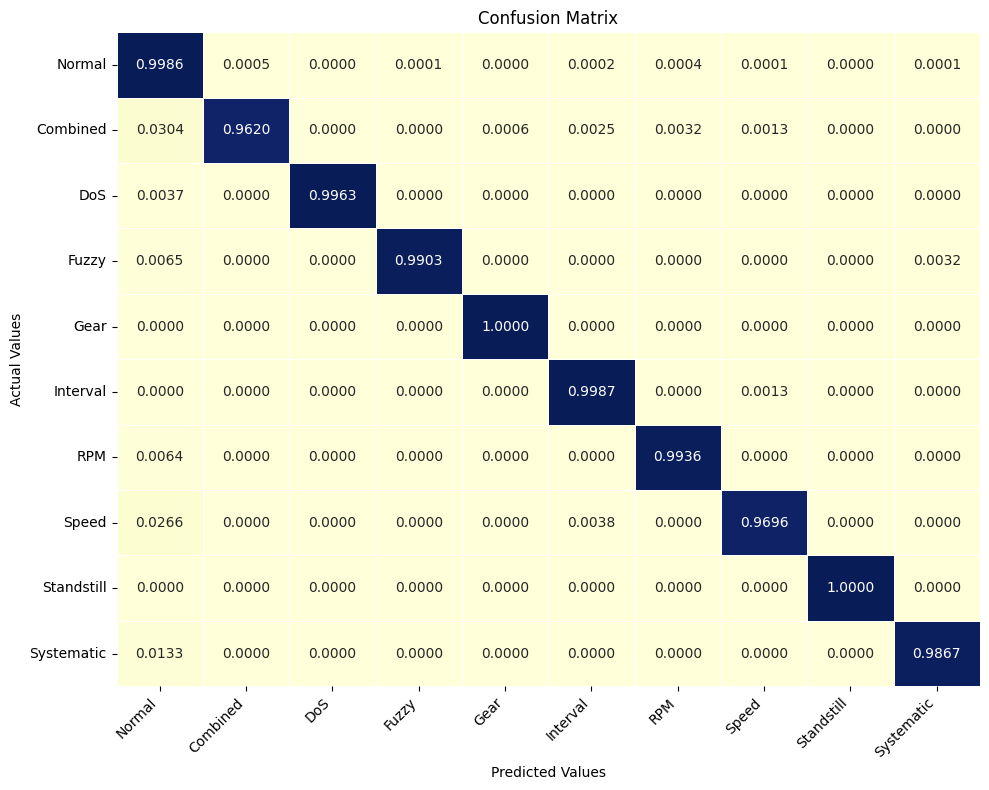

In [16]:
#### visualize confusion matrix
draw_confusion_matrix(conf_matrix, target_names, save_file='../images/CAN-ML/ResCNN-Transformer/conf_matrix.png')